# Régression logistique (classification des fleurs d’iris) 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.linear_model import LogisticRegression

iris = datasets.load_iris()
X = iris.data[:, :2]              # sepal length, sepal width
y = (iris.target != 0) * 1        # 0 = setosa, 1 = versicolor or virginica

print(X.shape, np.bincount(y))    # (150, 2) [ 50 100]

(150, 2) [ 50 100]


### Q7) Visualisation des données

Le nuage représente les 150 fleurs selon la longueur et la largeur du sépale (50 setosa en classe 0, 100 versicolor/virginica en classe 1).

**Interprétation :**
- Les deux classes forment deux groupes **bien distincts** :
  - **Setosa (0)** : sépales **courts et larges** (longueur ≈ 4,3–5,8 cm, largeur ≈ 2,3–4,4 cm), en haut à gauche.
  - **Non-setosa (1)** : sépales **plus longs et plus étroits** (longueur ≈ 4,9–7,9 cm, largeur ≈ 2–3,8 cm), en bas à droite.
- On peut tracer une **droite** qui sépare parfaitement les deux groupes : les données sont **linéairement séparables**. La régression logistique, classifieur linéaire, est donc bien adaptée.
- Les classes sont **déséquilibrées** (50 contre 100), conséquence du regroupement de versicolor et virginica.
- **Point atypique** : une setosa (4,5 ; 2,3) a un sépale anormalement étroit et se situe près des fleurs non-setosa. Les classes restent néanmoins séparables par une droite, mais ce point contraint fortement la position de la frontière.

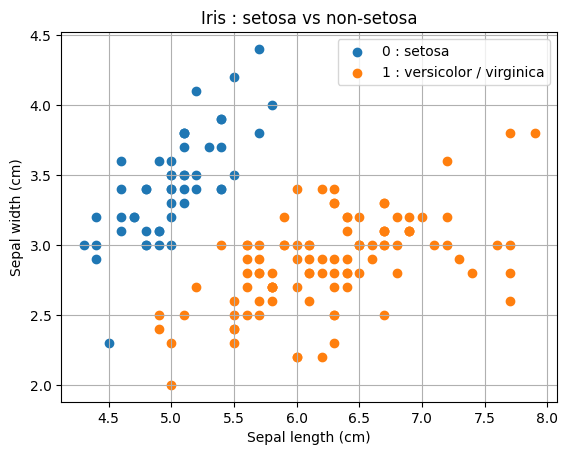

In [2]:
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='tab:blue', label='0 : setosa')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='tab:orange', label='1 : versicolor / virginica')
plt.xlabel('Sepal length (cm)'); plt.ylabel('Sepal width (cm)')
plt.title('Iris : setosa vs non-setosa')
plt.legend(); plt.grid(True); plt.show()

Step 3: Training

In [3]:
model = LogisticRegression(C=1e20)
model.fit(X, y)
print("w =", model.coef_, " b =", model.intercept_)
print("Accuracy (train) :", model.score(X, y))

w = [[ 69.83261087 -79.81650518]]  b = [-134.10250544]
Accuracy (train) : 1.0


### Q8) Prédiction de nouvelles fleurs

Frontière de décision apprise : $69{,}83\,x_1 - 79{,}82\,x_2 - 134{,}10 = 0 \iff x_2 \approx 0{,}875\,x_1 - 1{,}68$
(au-dessus de la droite → setosa ; en dessous → non-setosa).

| Point (longueur, largeur) | Classe prédite | Vérification sur le scatter |
|---|---|---|
| [5,5 ; 2,5] | **1** (non-setosa) | sépale moyen et étroit → dans le groupe orange |
| [7 ; 3] | **1** (non-setosa) | sépale long → nettement dans le groupe orange |
| [3 ; 2] | **0** (setosa) | hors des données (longueur min observée = 4,3) : extrapolation, prédiction peu fiable |
| [5 ; 3] | **0** (setosa) | sépale court et large → dans le groupe bleu |

**Remarques :**
- Les probabilités prédites valent exactement 0 ou 1 : avec `C=1e20` (pas de régularisation) et des données linéairement séparables, les poids deviennent très grands et le modèle est **sur-confiant**.
- Le point [3 ; 2] se trouve en dehors de la zone couverte par les données : le modèle le classe selon la position par rapport à la droite, mais aucune fleur réelle ne ressemble à ce point.

[1 1 0 0]
[[0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]


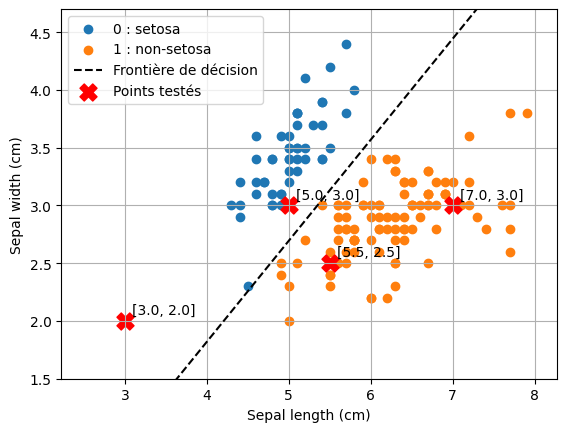

In [4]:
tests = np.array([[5.5, 2.5], [7, 3], [3, 2], [5, 3]])
print(model.predict(tests))
print(model.predict_proba(tests).round(4))

# Decision boundary: w1*x1 + w2*x2 + b = 0  =>  x2 = -(w1*x1 + b) / w2
w1, w2 = model.coef_[0]; b = model.intercept_[0]
xs = np.linspace(2.5, 8, 100)
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='tab:blue', label='0 : setosa')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='tab:orange', label='1 : non-setosa')
plt.plot(xs, -(w1 * xs + b) / w2, 'k--', label='Frontière de décision')
plt.scatter(tests[:, 0], tests[:, 1], c='red', marker='X', s=150, label='Points testés')
for p in tests:
    plt.annotate(str(list(p)), p, textcoords='offset points', xytext=(5, 5))
plt.xlabel('Sepal length (cm)'); plt.ylabel('Sepal width (cm)')
plt.ylim(1.5, 4.7); plt.legend(); plt.grid(True); plt.show()

**Observations sur le graphique :**
- La frontière passe **très près de deux fleurs** : la setosa atypique (4,5 ; 2,3), juste au-dessus de la droite, et la fleur non-setosa (5,4 ; 3,0), juste en dessous. La **marge** entre les classes est donc très faible : le modèle sépare parfaitement les données d'apprentissage (accuracy 100 %), mais une nouvelle fleur proche de cette zone pourrait facilement être mal classée.
- Le point [3 ; 2] est loin de toutes les données ; il est classé setosa uniquement parce qu'il est au-dessus du prolongement de la droite (à x = 3, la frontière passe à y ≈ 0,95). C'est une **extrapolation** sans réelle justification.